## Module 2: FSHD Clinical Trial Project

## Project Goal:

Our Biomarkers and Clinical Outcomes team has been tasked to design an early-stage clinical trial for a new Facioscapulohumeral Muscular Dystrophy (FSHD) treatment. We are analyzing natural-history data from 34 patients in a longitudinal study over 2 years to determine which measures should be used in the clinical trial as exploratory endpoints. There has been much debate within the field as to which measures best represent the progression of the disease over time. FSHD affects patients across several realms—not only biologically, but in terms of physical function, mobility, and overall quality of life. By the end of our investigation we hope to answer the question: 

What measure exhibits the best combination of sensitivity to treatment effects, reproducibility, and clinical relevance for assessing FSHD patients over time?



## Disease Background: 

Facioscapulohumeral muscular dystrophy (FSHD) is a rare genetic disease that causes the degeneration of skeletal muscles. In particular, muscle weakness most commonly begins in the face (facio), shoulders (scapula), and upper arms (humerus), but can eventually affect any muscle in the body. It is estimated that around 1 in 8,000 individuals, or 870,000 people worldwide are affected by this disease. While around 70% of cases are inherited from an affected parent, the remaining 30% arise from spontaneous genetic mutations in individuals with no prior family history of FSHD (FSHD Society, 2025). Both types of FSHD, FSHD1 and FSHD2, involve the abnormal expression of the toxic protein DUX4. In FSHD1 and FSHD2, the loss of D4Z4 repeats and demethylation of the DNA allows for the epigenetic derepression and sequential translation of the protein. This protein is toxic to muscle cells, and leads to their eventual degradation and death (Statland & Tawil, 2016). FSHD symptoms vary widely in terms of onset, presentation, and severity. 10 percent of individuals show symptoms before the age of 10. Most commonly, it presents anywhere from the ages of 15-30, though symptoms can onset at any age. Classic signs include the weakening of facial muscles, with the loss of ability to fully close the eyes, purse the lips, or turn the corners of the mouth “up” into a smile being characteristic signs. The degradation of certain muscle groups eventually severely affects mobility, with 20% of people with FSHD needing wheelchairs before 50 (FSHD Society, 2025). FSHD diagnosis typically involves a clinical evaluation, family history check, and genetic testing to confirm the condition. Those with early-onset FSHD may need specialized treatment with mobility aids, and are at a higher risk for vision or hearing problems. Managing FSHD focuses on alleviating symptoms, maximizing quality of life, and maintaining mobility and physical function. The disease progression is unique from person to person, with some that progress severely and rapidly, and others who experience a slow but gradual decline. As of now, there is no effective treatment or cure for FSHD. However, the field of FSHD research is vast, and many clinical trials aim to epigenetically enhance the repression of the D4Z4 gene, target the DUX4 mRNA, and inhibit or block the activity of DUX4. The FSHD community holds great hope for clinical research to advance treatment options and eventually lead to a cure (Wang, Tawil, & Bonne, 2021). 

## Data Set:

This project uses MRI data of the tibialis anterior (TA), the muscle on the front of the lower leg that lifts the foot. The data come from the Wellstone Muscular Dystrophy Cooperative Research Center study of FSHD, which enrolled 34 people (16 female and 18 male) aged 21 to 69 (Wong et al., 2024). We analyzed one subject, UW_0020, at two visits, TP1 and TP2. Each visit has 8 slices (cross-sections of the leg) spaced from 10% to 80% of the way along the muscle. The file slice_info.csv lists each slice’s position as a percent and as a distance in millimeters from the start of the muscle. Each slice has three NumPy files a water image, a fat image, and a mask. The water and fat images come from a Dixon MRI scan, which separates the signal from water and the signal from fat. Brighter pixels mean more of that tissue. Both images are in arbitrary signal units, so the numbers only have meaning when compared with each other, and we use them to calculate fat fraction as a percent. The mask marks which pixels are TA muscle. In the study, the TA was outlined by an AI program from Springbok Analytics and then checked by hand (Wong et al., 2024). We were given the finished masks. The full study also collected strength, a clinical severity score, a STIR inflammation rating, and biopsy gene data, but our files contain only the MRI slices.

## MRI Data Analysis Methdology:

This analysis reproduces how one MRI dataset was generated, using one subject (UW_0020) at two visits (TP1 and TP2). Each visit has eight cross-sectional slices along the tibialis anterior (TA), each with a water image, a fat image, and a muscle mask. We load the files, use the mask to isolate the TA, calculate fat fraction, summarize it, and compare locations and visits.

We load the packages and read slice_info.csv into a table called manifest. Each of its 16 rows is one slice (8 per visit) and lists the slice’s location along the muscle and the names of its water, fat, and mask files.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


We load the water image, fat image, and mask for one TP1 slice, slice 04, which is 40% along the muscle. The mask is converted so that each pixel is either muscle (true) or not muscle (false). All three images are 266 × 224 pixels, so they line up pixel for pixel. The mask contains 360 muscle pixels.

In [5]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


Fat fraction is fat signal divided by (water signal + fat signal), times 100. Pixels where the total is zero are set to 0 so we never divide by zero. We calculate it for the whole image region and for the TA only, where pixels outside the mask are set to NaN so they are ignored. For slice 04, the mean fat fraction is 48.6% for the whole region and 29.9% for the TA only (range 0.5% to 90.7%).

In [6]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")


Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


We generate Figure 1 which will show the water image, the fat image, the whole-region fat fraction, and a zoomed TA-only fat fraction map. The mask outline lets us check that it sits on the TA. Both fat fraction maps use the same 0 to 100% color scale.

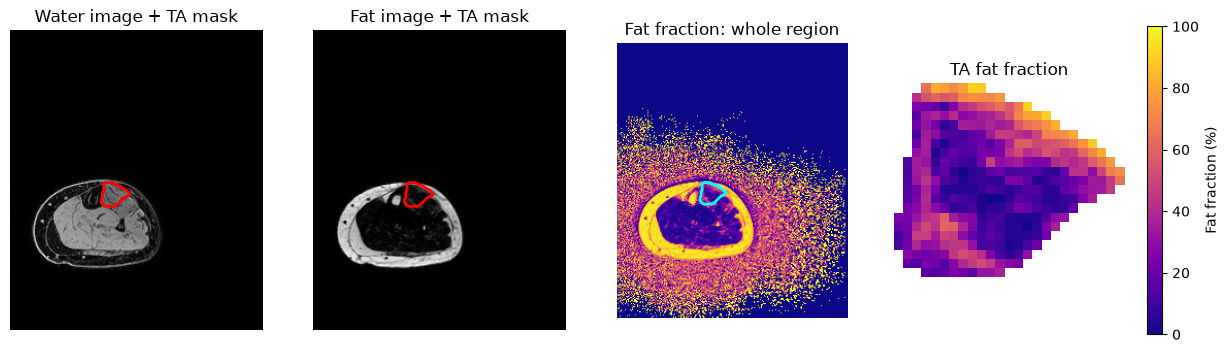

In [7]:
# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()

Figure 1. Water image, fat image, whole-region fat fraction, and TA-only fat fraction for TP1 slice 04 (40% along the muscle). The outline marks the TA mask. This figure shows that the mask picks out the muscle from the rest of the leg. We can conclude that the mask sits on the TA, and that fat fraction inside the muscle is mostly low to moderate, with higher values along its upper edge.

Now, Figure 2 will show histograms of fat fraction for the whole region and for the TA only, so we can see how the values are spread out and not just their average.

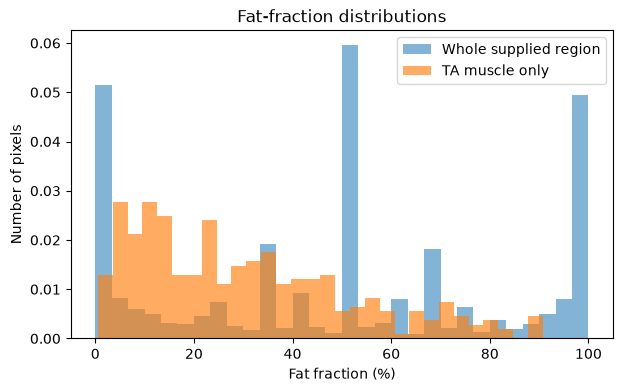

In [11]:
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region", density=True)
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only", density=True)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions")
plt.legend()
plt.show()


Figure 2. Histograms of fat fraction (%) for the whole supplied region and the TA only, for TP1 slice 04. The whole region has large peaks near 0%, 50%, and 100% because it includes air, noise, subcutaneous fat, and other tissue. The TA-only values have a median of 25.4% and a mean of 29.9%, which means most pixels have lower fat but a tail of high-fat pixels pulls the mean up. This figure shows why the mask is needed, since whole-region values do not describe the muscle.

We put the fat fraction calculation into a function and loop through all 8 TP1 slices. For each slice we record the mean, median, standard deviation, and number of muscle pixels, along with its location. The pixel count shows whether the muscle area changed, and the median is less affected by a few very fatty pixels.

In [9]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df


,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.924382,88.827837,13.272006,61
1,UW_0020,TP1,2,20,44.0,82.706905,86.651582,12.433905,115
2,UW_0020,TP1,3,30,68.0,58.498513,61.821705,22.878862,231
3,UW_0020,TP1,4,40,92.0,29.931733,25.369646,21.584495,360
4,UW_0020,TP1,5,50,116.0,20.866866,14.553991,20.060150,421
5,UW_0020,TP1,6,60,136.0,16.758732,9.049959,19.665424,440
6,UW_0020,TP1,7,70,160.0,17.511838,8.962264,20.456168,388
7,UW_0020,TP1,8,80,184.0,27.873337,22.685185,22.625359,263


Table 1. Muscle-only fat fraction for each TP1 slice. Mean fat fraction is highest at the start of the muscle (83.9% at 24 mm) and lowest in the middle (16.8% at 136 mm). It rises again at the far end (27.9% at 184 mm). The median is lower than the mean in the middle slices (for example 25.4% vs 29.9% at 92 mm), which means a few very fatty pixels pull the mean up. The slices at 24 mm and 44 mm contain the fewest muscle pixels (61 and 115), so their values come from a small area.

We repeat the calculation for TP2 and plot mean TA fat fraction against location for both visits. We assume slices at the same percent position are at about the same part of the muscle at both visits. The distances in millimeters differ slightly between visits (TP1 ends at 184 mm and TP2 at 196 mm), so this is only approximate.

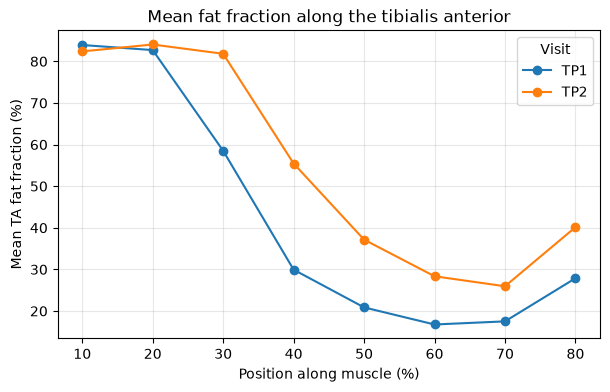

In [12]:
def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["percent_along_muscle"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Position along muscle (%)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()


This figure shows how fat is spread along the muscle and whether it changed between visits. Both visits show the same pattern: fat is highest near the start of the muscle and lowest in the middle. Fat fraction is similar at the first two locations but higher at TP2 from about 30% onward (roughly 55% vs 30% at 40%). We can conclude that fat increased between visits, mostly in the middle and far parts of the muscle. This is a change in muscle composition and does not by itself show a change in patient function.

## Interpolation Analysis:

Explain how interpolation was used to estimate fat fraction or another measurement at a location between sampled points along the tibialis anterior.

Include:

- The variable used to define location along the muscle, such as distance in millimeters or percentage of muscle length
- The sampled locations used as inputs to the interpolation
- The interpolation method and Python code used
- A plot showing the measured values and the interpolated estimate(s)
- Why interpolation is an estimate rather than a new measurement
- The assumptions made about how the measurement changes between sampled locations
- Whether the estimate is within the range of sampled data or represents extrapolation
- Any limitations or sources of uncertainty in the interpolated result

## Conclusions:

Explain what your analysis suggests about measuring FSHD progression.

Discuss:

- Which MRI, biomarker, or functional measures changed most consistently
- Which measures appeared most sensitive to differences across muscle locations or visits
- Whether the measures could be useful as biomarkers or exploratory clinical-trial endpoints
- What additional evidence would be needed before using them to evaluate treatment effectiveness
- Potential ethical implications of selecting one measure over another, including patient relevance, accessibility, and the risk of overlooking meaningful changes in function

## Limitations and Future Work:

Describe the limitations of your project, including limitations of the sample size, available visits, MRI measurements, segmentation, biomarkers, functional measures, and analysis methods.

If you had more time or additional data, explain how you would improve the analysis. Examples include analyzing more participants, adding more timepoints, improving segmentation, comparing additional muscles, validating the MRI measure against functional outcomes, or testing whether the measure is sensitive to treatment response.

## AI Usage Statement:

Claude was used to assist in analysis in the results shown by the figures and tables, which helped write the conclusions by ourselves.

## GitHub Repository Link:

https://github.com/artyrchuk/BME_2315_Module2.git

## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*
Statland, J. M., & Tawil, R. (2016). Facioscapulohumeral muscular dystrophy. Continuum, 22(6), 1916–1931. https://doi.org/10.1212/con.0000000000000399

Understanding FSHD - FSHD society. FSHD Society - Empowering FSHD Patients, Accelerating FSHD Progress. (2025, April 18). https://www.fshdsociety.org/living-with-fshd/understanding-fshd/

Wang LH, Tawil R, Bonne G. Current Therapeutic Approaches in FSHD. Journal of Neuromuscular Diseases. 2021;8(3):441-451. doi:10.3233/JND-200554 

Wong, C. J., Friedman, S. D., Snider, L., Bennett, S. R., Jones, T. I., Jones, P. L., Shaw, D. W. W., Blemker, S. S., Riem, L., DuCharme, O., Lemmers, R. J. F. L., van der Maarel, S. M., Wang, L. H., Tawil, R., Statland, J. M., & Tapscott, S. J. (2024). Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. Human molecular genetics, 33(8), 698–708. https://doi.org/10.1093/hmg/ddae007


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*